# AI-Based Semiconductor Wafer Defect Classification

Step-by-step notebook. Cells are added one stage at a time.

## Stage 1: Load and inspect the dataset

Goal: confirm the file loads, and learn its shape, columns, types and missing values. No modelling yet.

Findings from Stage 1:
- 811,457 rows and 6 columns: `waferMap`, `dieSize`, `lotName`, `waferIndex`, `trianTestLabel` (the dataset spells it this way), `failureType`.
- No missing values. Labels are stored as nested arrays such as `[['none']]`, so they must be unwrapped.
- 638,507 wafers are unlabelled. 172,950 are labelled (54,355 Training and 118,595 Test).
- Pixel values: 0 = off-wafer, 1 = good die, 2 = defective die. Wafer sizes vary, so features must not depend on the grid size.

In [6]:
# Cell 1: check how much RAM this PC has free
import psutil                                  # reads system information such as memory
mem = psutil.virtual_memory()                  # current RAM statistics
print(f"Total RAM: {mem.total / 1e9:.1f} GB")  # convert bytes to gigabytes
print(f"Free RAM:  {mem.available / 1e9:.1f} GB")

Total RAM: 16.9 GB
Free RAM:  6.7 GB


In [7]:
# Cell 2: load the dataset file once and look at its size and columns
import pickle                                  # Python's built-in tool for reading saved objects
import pandas as pd                            # pandas: library for tables of data

DATA_PATH = r"C:\Users\Shashank Savarkar\OneDrive\Documents\TY ECE\5th Sem\AIML\Project\AIML_Project\LSWMD.pkl"  # path to the file (r"" keeps the backslashes)

# The file was saved with an old pandas version. Current pandas moved some module paths,
# so we map the old names to the new ones while reading.
RENAMES = {
    "pandas.indexes.base": "pandas.core.indexes.base",    # old path -> new path
    "pandas.indexes.range": "pandas.core.indexes.range",
}

class OldPandasUnpickler(pickle.Unpickler):   # a reader that understands the old paths
    def find_class(self, module, name):       # Python calls this for every class named in the file
        return super().find_class(RENAMES.get(module, module), name)  # swap the path if we know it

with open(DATA_PATH, "rb") as f:              # open the file in binary mode
    df = OldPandasUnpickler(f, encoding="latin1").load()  # latin1: the text encoding used by Python 2 files

print("Shape (rows, columns):", df.shape)     # how many wafers and fields
print("Columns:", list(df.columns))           # names of the fields
print(df.dtypes)                              # data type of each column

Shape (rows, columns): (811457, 6)
Columns: ['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']
waferMap           object
dieSize           float64
lotName            object
waferIndex        float64
trianTestLabel     object
failureType        object
dtype: object


In [8]:
# Cell 3: look at sample rows, missing values and the label columns
print(df.head(3))                              # first 3 rows, to see what the data looks like

print("\nMissing values per column:")
print(df.isna().sum())                         # count of empty (NaN) values in each column

if "trianTestLabel" in df.columns:             # only run if this column exists (we verify, not assume)
    print("\ntrianTestLabel counts:")
    print(df["trianTestLabel"].astype(str).value_counts())  # how many training vs test wafers

if "failureType" in df.columns:                # the defect label column
    print("\nfailureType counts (top 15, text shortened):")
    print(df["failureType"].astype(str).str[:40].value_counts().head(15))  # most common labels first

                                            waferMap  dieSize lotName  \
0  [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...   1683.0    lot1   
1  [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...   1683.0    lot1   
2  [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...   1683.0    lot1   

   waferIndex trianTestLabel failureType  
0         1.0   [[Training]]    [[none]]  
1         2.0   [[Training]]    [[none]]  
2         3.0   [[Training]]    [[none]]  

Missing values per column:
waferMap          0
dieSize           0
lotName           0
waferIndex        0
trianTestLabel    0
failureType       0
dtype: int64

trianTestLabel counts:
trianTestLabel
[]                638507
[['Test']]        118595
[['Training']]     54355
Name: count, dtype: int64

failureType counts (top 15, text shortened):
failureType
[]                 638507
[['none']]         147431
[['Edge-Ring']]      9680
[['Edge-Loc']]       5189
[['Center']]         4294
[['Loc']]            3593
[['Scratch']]       

## Stage 2: Dataset exploration and visualisation

Goal: understand the labels, the pixel meanings and the wafer patterns before extracting features.

First we turn the nested label arrays into plain text. Unlabelled wafers get the marker `unlabelled`.

In [9]:
# Cell 4: turn the nested label arrays into plain text, and mark unlabelled wafers
import numpy as np                             # numerical arrays (the wafer maps are arrays)

def unwrap(value):                             # the label is stored as [['none']]; this returns just 'none'
    arr = np.asarray(value)                    # convert to a numpy array so we can read its first item
    return str(arr.ravel()[0]) if arr.size else ""  # first item as text, or "" if the array is empty

df["failure"] = df["failureType"].map(unwrap)                             # defect name, e.g. 'none', 'Center'
df["split"] = df["trianTestLabel"].map(lambda v: unwrap(v) or "unlabelled")  # Training / Test / unlabelled

labelled = df[df["split"] != "unlabelled"]     # keep only wafers that have a label
print("Labelled wafers:", len(labelled))       # expected 172,950
print("Unlabelled wafers:", (df["split"] == "unlabelled").sum())  # expected 638,507

Labelled wafers: 172950
Unlabelled wafers: 638507


In [10]:
# Cell 5: check what the pixel values mean and how big the wafer maps are
example = np.asarray(labelled["waferMap"].iloc[0])  # one wafer map: a 2D grid of numbers
print("Example shape (rows, cols):", example.shape)
print("Pixel values present:", np.unique(example))  # expected 0, 1 and 2
for v in [0, 1, 2]:                            # share of each pixel value in this map
    print(f"  pixel {v}: {np.mean(example == v):.1%}")

# Sizes vary between wafers, so check the most common sizes across labelled wafers
sizes = labelled["waferMap"].map(lambda w: np.asarray(w).shape).value_counts().head(5)  # top 5 sizes
print("\nMost common wafer map sizes:")
print(sizes.to_string())

Example shape (rows, cols): (45, 48)
Pixel values present: [0 1 2]
  pixel 0: 22.1%
  pixel 1: 73.8%
  pixel 2: 4.1%

Most common wafer map sizes:
waferMap
(25, 27)    18781
(26, 26)    14366
(30, 34)    12400
(29, 26)    11751
(27, 25)    10682


failure
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149


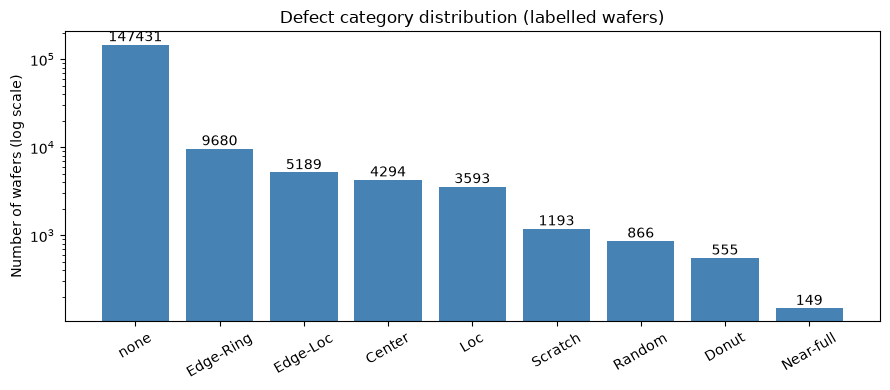

In [11]:
# Cell 6: how many wafers each defect category has (bar chart saved to reports/figures)
import matplotlib.pyplot as plt                # plotting library
from pathlib import Path                       # easy handling of folder paths

FIG_DIR = Path("../reports/figures")           # the notebook sits in notebooks/, so go up one level
FIG_DIR.mkdir(parents=True, exist_ok=True)     # create the folder if it does not exist yet

counts = labelled["failure"].value_counts()    # number of wafers per category, largest first
print(counts.to_string())

fig, ax = plt.subplots(figsize=(9, 4))         # one chart, 9 x 4 inches
bars = ax.bar(counts.index, counts.values, color="steelblue")  # one bar per category
ax.set_yscale("log")                           # log scale, so the small classes stay visible
ax.set_ylabel("Number of wafers (log scale)")
ax.set_title("Defect category distribution (labelled wafers)")
ax.bar_label(bars, fmt="%d")                   # write each count above its bar
plt.xticks(rotation=30)                        # tilt the category names so they fit
plt.tight_layout()                             # stop labels being cut off
fig.savefig(FIG_DIR / "label_distribution.png", dpi=150)  # save the image for the report
plt.show()

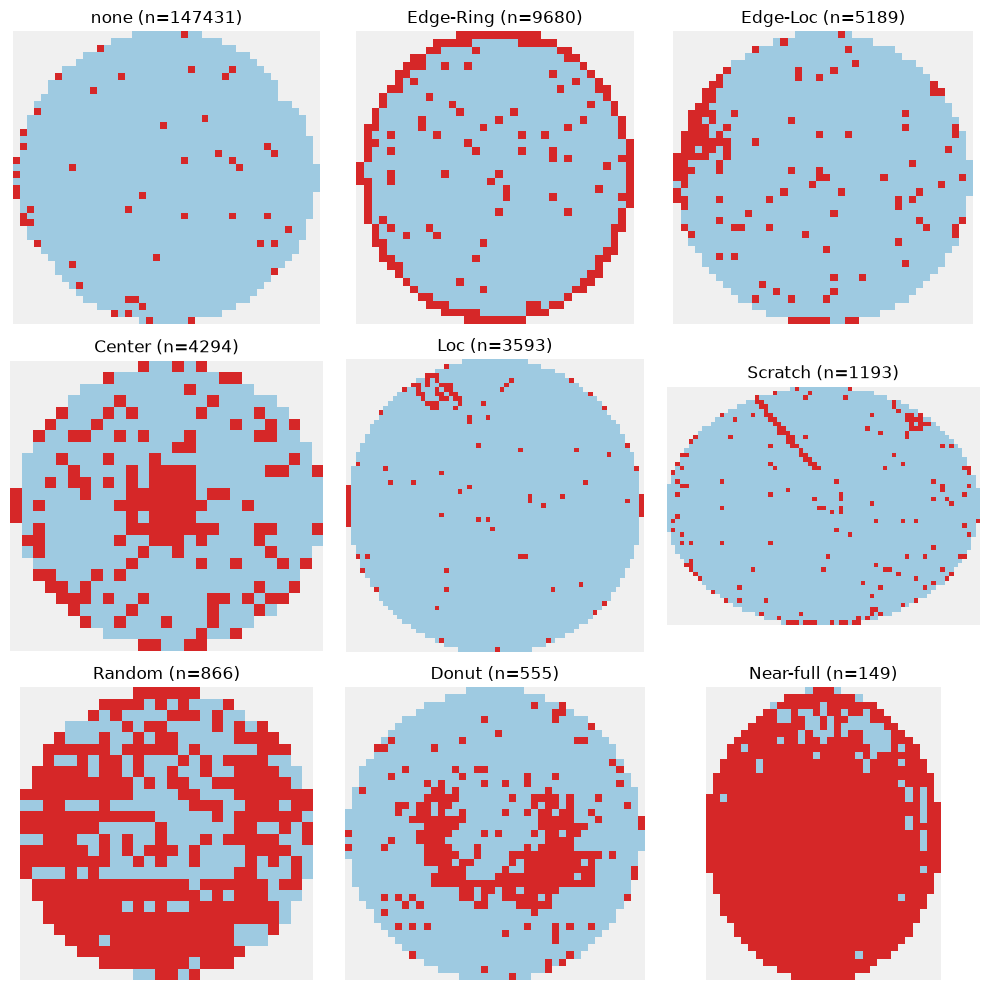

In [12]:
# Cell 7: one example wafer for each defect category (gallery saved to reports/figures)
from matplotlib.colors import ListedColormap   # lets us choose the colour for each pixel value

# Colours: 0 = off-wafer (grey), 1 = good die (blue), 2 = defective die (red)
cmap = ListedColormap(["#f0f0f0", "#9ecae1", "#d62728"])

classes = counts.index.tolist()                # the category names, in the same order as Cell 6
fig, axes = plt.subplots(3, 3, figsize=(10, 10))  # a 3 x 3 grid of pictures
for ax, name in zip(axes.ravel(), classes):    # go through the grid cells and the category names together
    wafer = labelled[labelled["failure"] == name].sample(1, random_state=1)["waferMap"].iloc[0]  # one random example
    ax.imshow(np.asarray(wafer), cmap=cmap, vmin=0, vmax=2)  # draw the pixel grid with our colours
    ax.set_title(f"{name} (n={counts[name]})")  # title with the category and its count
    ax.axis("off")                             # hide the axis numbers
for ax in axes.ravel()[len(classes):]:         # hide any unused grid cells
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "wafer_gallery.png", dpi=150)  # save the image for the report
plt.show()

## Stage 3: Preprocessing

Goal: make the data clean and in the form the models need. Every step below is explained.

1. **Keep only labelled wafers.** Unlabelled wafers have no answer to learn from, so they are removed (done in Stage 2).
2. **Remove wafers with no dies.** A map with no die positions cannot give a defect density, so it is dropped.
3. **Give each category a number.** The models predict numbers, so each defect name gets an ID.
4. **Keep all 9 categories, including the small ones.** We do not delete the rare classes (Near-full has 149 wafers, Donut 555). Deleting them would hide the patterns the project is about. Instead, Stage 6 uses class weights, and we report results per class.
5. **Do not use the labels as inputs.** `failure` and `target` are only the answer, never a feature (Stage 4 enforces this).

In [13]:
# Cell 9: find wafer maps that cannot be used (no die positions at all)
def count_dies(w):                                  # count the die positions on one wafer
    a = np.asarray(w)                               # the wafer map as a numpy grid
    return int(np.sum(a > 0))                       # 0 = off-wafer, so any value above 0 is a die (1 good, 2 defective)

labelled = labelled.copy()                          # work on our own copy, avoids pandas warnings
labelled["n_dies"] = labelled["waferMap"].map(count_dies)  # number of die positions on each wafer
empty = labelled[labelled["n_dies"] == 0]           # wafers with no dies at all
print("Maps with no dies:", len(empty))             # expected 0 or a small number
labelled = labelled[labelled["n_dies"] > 0]         # keep only usable wafers (density needs at least one die)
print("Wafers kept:", len(labelled))

Maps with no dies: 0
Wafers kept: 172950


In [14]:
# Cell 10: give each defect category a number (the models need numbers, not words)
CLASS_NAMES = sorted(labelled["failure"].unique())  # alphabetical list of the category names
label_to_id = {name: i for i, name in enumerate(CLASS_NAMES)}  # e.g. {'Center': 0, 'Donut': 1, ...}
id_to_label = {i: name for name, i in label_to_id.items()}     # reverse lookup, to show predictions as names
labelled["target"] = labelled["failure"].map(label_to_id)      # new column: the number the model will learn to predict

print(label_to_id)
print(labelled["target"].value_counts().sort_index().to_string())  # wafers per class ID

{'Center': 0, 'Donut': 1, 'Edge-Loc': 2, 'Edge-Ring': 3, 'Loc': 4, 'Near-full': 5, 'Random': 6, 'Scratch': 7, 'none': 8}
target
0      4294
1       555
2      5189
3      9680
4      3593
5       149
6       866
7      1193
8    147431


## Stage 4: Feature extraction

Goal: turn each wafer map (a grid of pixels) into one row of numbers, so classical models can learn from it. The code lives in `src/features.py`, so the demo app will use exactly the same function.

Features (15 numbers per wafer):
- **Counts:** `n_dies` (die positions), `n_defects` (defective dies).
- **Defect density:** `defect_density` = defects / dies.
- **Region densities:** the wafer is split by distance from its centre into `center`, `mid` and `edge` thirds.
- **Left/top balance:** `left_frac` and `top_frac`, the share of defects on the left half and top half (0.5 = balanced).
- **Spatial spread:** `x_spread`, `y_spread` (how far defects spread, scaled by map size) and `mean_radius` (how close to the edge defects sit on average).
- **Lines:** `max_row_density` and `max_col_density`, the worst single row or column. A scratch or a line shows up here.
- **Clusters:** `n_clusters` (groups of touching defects) and `largest_cluster_frac` (share of defects in the biggest group).

The label `failure` is never a feature. It is only the answer.

In [15]:
# Cell 12: turn every labelled wafer map into a row of numbers (features)
import sys                                         # lets Python find our src folder
sys.path.append("..")                            # the notebook is in notebooks/, so src/ is one level up
from src.features import extract_features, FEATURE_NAMES  # our feature function and the list of feature names

feature_rows = [extract_features(w) for w in labelled["waferMap"]]  # one dictionary of features per wafer
X = pd.DataFrame(feature_rows, index=labelled.index)[FEATURE_NAMES]  # table: one row per wafer, one column per feature
print("Feature table shape:", X.shape)           # expected (172950, 15)
print("Missing feature values:", int(X.isna().sum().sum()))  # expected 0
X.head()

Feature table shape: (172950, 15)
Missing feature values: 0


,n_dies,n_defects,defect_density,center_density,mid_density,edge_density,left_frac,top_frac,x_spread,y_spread,mean_radius,max_row_density,max_col_density,n_clusters,largest_cluster_frac
0,1683.0,88.0,0.052288,0.035533,0.042662,0.062222,0.522727,0.545455,0.277648,0.266824,0.714767,0.166667,0.428571,81.0,0.034091
1,1683.0,86.0,0.051099,0.040609,0.032423,0.065556,0.360465,0.488372,0.285324,0.255767,0.746862,0.333333,0.714286,72.0,0.069767
2,1683.0,66.0,0.039216,0.020305,0.013652,0.060000,0.378788,0.484848,0.301249,0.294170,0.796288,0.500000,0.428571,62.0,0.045455
3,1683.0,104.0,0.061794,0.035533,0.042662,0.080000,0.519231,0.557692,0.286004,0.280309,0.745445,0.833333,0.714286,87.0,0.038462
4,1683.0,71.0,0.042187,0.005076,0.039249,0.052222,0.422535,0.521127,0.296303,0.255256,0.751648,0.250000,0.428571,64.0,0.028169


In [16]:
# Cell 13: check the feature ranges and save the table for later stages
print(X.describe().T.round(3).to_string())         # min, mean and max of each feature
Path("../data/processed").mkdir(parents=True, exist_ok=True)  # make sure the folder exists
X.to_csv(Path("../data/processed/features.csv"))  # save, so we do not recompute the features next time
print("Saved features.csv")

                         count      mean       std  min      25%      50%       75%        max
n_dies                172950.0  1042.232  1032.572  3.0  533.000  776.000  1250.000  22372.000
n_defects             172950.0   105.845    98.151  0.0   63.000   85.000   110.000   5494.000
defect_density        172950.0     0.118     0.074  0.0    0.069    0.106     0.151      1.000
center_density        172950.0     0.111     0.111  0.0    0.048    0.083     0.140      1.000
mid_density           172950.0     0.084     0.074  0.0    0.040    0.067     0.107      1.000
edge_density          172950.0     0.142     0.080  0.0    0.087    0.130     0.183      1.000
left_frac             172950.0     0.498     0.073  0.0    0.455    0.498     0.540      1.000
top_frac              172950.0     0.492     0.074  0.0    0.448    0.492     0.536      1.000
x_spread              172950.0     0.270     0.023  0.0    0.255    0.269     0.283      0.404
y_spread              172950.0     0.271     0.023

## Stage 5: Train, validation and test split

Goal: split the data so the models are never judged on wafers they learned from.

We use the dataset's own split (`trianTestLabel`):
- **Training pool** (54,355 wafers): used to build and compare models.
- **Test set** (118,595 wafers): used **once**, at the end, for the final score.

The training pool is split again into **train** (fit the models) and **validation** (compare the models). The split keeps each production lot whole, so wafers from the same lot never sit on both sides. Class proportions are kept similar in each part (stratified).

Two facts found in the check:
- No lot appears in both Training and Test. The official split is already lot-separated.
- The Test set has far more "none" wafers (93%) than Training (68%). So accuracy on Test will look high. We judge models by macro-F1 and per-class recall instead.

In [17]:
# Cell 15: split the data and check that no lot leaks across the splits
from sklearn.model_selection import StratifiedGroupKFold  # keeps class proportions and keeps whole lots together

y = labelled["target"]                              # the answer for each wafer (a number 0 to 8)
groups = labelled["lotName"].astype(str)           # the production lot of each wafer
is_test = labelled["split"] == "Test"             # True for the official Test wafers

X_test, y_test = X[is_test], y[is_test]             # official Test set: used only once, at the end
X_pool, y_pool = X[~is_test], y[~is_test]           # official Training set: used to build and compare models
g_pool = groups[~is_test]                           # the lot of each training-pool wafer

# Split the training pool into train and validation parts. Each validation part is about 20%.
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)  # 5 folds, we use the first one
tr_idx, va_idx = next(sgkf.split(X_pool, y_pool, g_pool))              # row positions for train and validation
X_train, y_train = X_pool.iloc[tr_idx], y_pool.iloc[tr_idx]
X_val, y_val = X_pool.iloc[va_idx], y_pool.iloc[va_idx]

# Leakage checks: the sets of lots must not overlap
print("No lot shared by train and validation:", set(g_pool.iloc[tr_idx]).isdisjoint(set(g_pool.iloc[va_idx])))
print("No lot shared by Training and Test:  ", set(g_pool).isdisjoint(set(groups[is_test])))
print("Sizes -> train:", len(X_train), " validation:", len(X_val), " test:", len(X_test))

# Class counts in each part, shown with names
summary = pd.DataFrame({
    "train": y_train.map(id_to_label).value_counts(),
    "validation": y_val.map(id_to_label).value_counts(),
    "test": y_test.map(id_to_label).value_counts(),
}).fillna(0).astype(int)
print(summary.to_string())

No lot shared by train and validation: True
No lot shared by Training and Test:   True
Sizes -> train: 43486  validation: 10869  test: 118595
           train  validation    test
target                              
Center      2769         693     832
Donut        327          82     146
Edge-Loc    1934         483    2772
Edge-Ring   6843        1711    1126
Loc         1296         324    1973
Near-full     44          10      95
Random       487         122     257
Scratch      400         100     693
none       29386        7344  110701


## Stage 6: Train and compare the four models

Goal: train each model on the **train** part and score it on the **validation** part. The test set is not touched.

The four models (from the syllabus):
- **Decision Tree:** asks a series of yes/no questions on the features. Easy to explain. Can overfit, so its depth is limited.
- **Random Forest:** many decision trees, each trained on a random part of the data, voting together. More accurate and more stable than one tree.
- **SVM (RBF kernel):** finds a boundary between classes in feature space. Needs scaled features, so it sits in a pipeline with `StandardScaler`.
- **Logistic Regression:** a linear model that gives a probability for each class. Also scaled in a pipeline.

`class_weight="balanced"` tells each model to treat rare classes as more important, so it cannot ignore "Near-full" just because it is rare. No hyperparameter tuning yet, as the brief asks.

Scores:
- **Accuracy:** share of correct predictions. Misleading here, because most wafers are "none".
- **Macro-F1:** average F1 over the 9 classes, so every class counts equally. Our main score.
- **Defect recall:** share of truly defective wafers (any category other than "none") that the model flags as defective. The security-style score: a missed defect is the costly error.

In [18]:
# Cell 16: define the four models (no tuning yet, just sensible settings)
from sklearn.tree import DecisionTreeClassifier          # yes/no question tree
from sklearn.ensemble import RandomForestClassifier      # many trees voting together
from sklearn.svm import SVC                              # support vector machine (RBF kernel)
from sklearn.linear_model import LogisticRegression      # linear model giving class probabilities
from sklearn.pipeline import make_pipeline               # chains steps, so scaling is fitted on training data only
from sklearn.preprocessing import StandardScaler         # rescales each feature to mean 0, spread 1

models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=12, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=20, class_weight="balanced", n_jobs=-1, random_state=42),
    "SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced")),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
}
print("Models defined:", list(models))

Models defined: ['Decision Tree', 'Random Forest', 'SVM', 'Logistic Regression']


In [19]:
# Cell 17: train each model on the train part, then score it on the validation part
import time                                              # to measure how long each model takes
from sklearn.metrics import accuracy_score, f1_score, recall_score

NONE_ID = label_to_id["none"]                            # the number used for the "no defect" class (8)
is_defect_val = (y_val != NONE_ID).values                # True where the validation wafer really has a defect

trained, val_preds, rows = {}, {}, []
for name, model in models.items():
    t0 = time.time()                                     # start the stopwatch
    model.fit(X_train, y_train)                          # learn only from the train part
    pred = model.predict(X_val)                          # predict the validation part (never seen in training)
    trained[name], val_preds[name] = model, pred
    flagged = (pred != NONE_ID)                          # True where the model says "defect"
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_val, pred),
        "macro_F1": f1_score(y_val, pred, average="macro"),
        "defect_recall": (flagged & is_defect_val).sum() / is_defect_val.sum(),
        "seconds": round(time.time() - t0, 1),
    })
    print(f"{name}: done in {rows[-1]['seconds']} s")

results = pd.DataFrame(rows).set_index("model").round(4)  # one row per model
print(results.to_string())
Path("../reports").mkdir(parents=True, exist_ok=True)
results.to_csv(Path("../reports/validation_results.csv"))  # save the table for the report

# Recall for each defect class, per model: shows which classes each model struggles with
per_class = pd.DataFrame(
    {name: recall_score(y_val, pred, average=None, labels=list(range(len(CLASS_NAMES))))
     for name, pred in val_preds.items()},
    index=CLASS_NAMES,
).round(3)
print("\nPer-class recall on validation:")
print(per_class.to_string())

Decision Tree: done in 1.0 s
Random Forest: done in 2.6 s
SVM: done in 42.6 s
Logistic Regression: done in 10.1 s
                     accuracy  macro_F1  defect_recall  seconds
model                                                          
Decision Tree          0.9084    0.7576         0.9884      1.0
Random Forest          0.9680    0.8595         0.9878      2.6
SVM                    0.9466    0.8288         0.9952     42.6
Logistic Regression    0.9203    0.7501         0.9901     10.1

Per-class recall on validation:
           Decision Tree  Random Forest    SVM  Logistic Regression
Center             0.877          0.973  0.954                0.870
Donut              0.854          0.890  0.963                0.927
Edge-Loc           0.764          0.911  0.882                0.793
Edge-Ring          0.925          0.960  0.959                0.947
Loc                0.534          0.744  0.685                0.528
Near-full          1.000          1.000  1.000               

## Stage 7: Evaluation and comparison

Goal: see *where* each model makes mistakes, not just how often.

- **Comparison plots:** accuracy and macro-F1 for the four models side by side.
- **Confusion matrices:** rows are the true class, columns are the predicted class. A perfect model puts everything on the diagonal. Each row is shown as a percentage of that true class, so small classes are readable.
- **Classification report:** precision, recall and F1 for each class, for the best model on validation.

Precision answers "when the model says X, how often is it right?". Recall answers "of all the real X wafers, how many did the model find?".

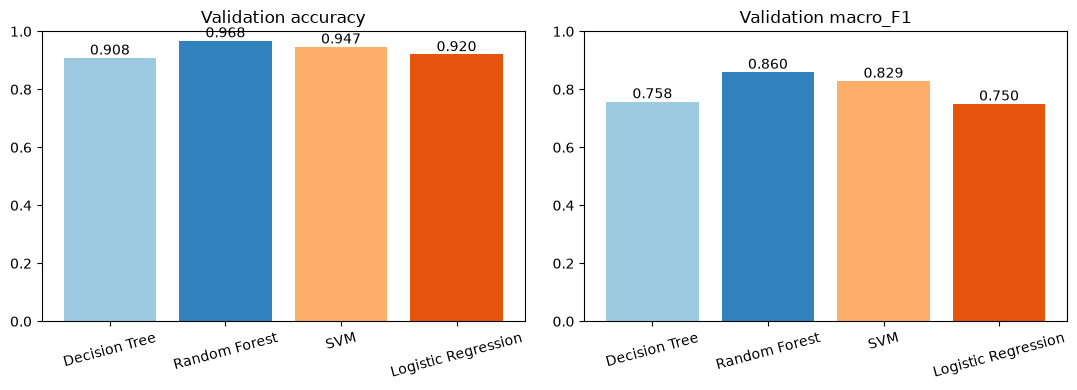

In [20]:
# Cell 20: compare the four models side by side (accuracy and macro-F1)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 4))            # two charts next to each other
for ax, metric in zip(axes, ["accuracy", "macro_F1"]):    # one chart for each score
    bars = ax.bar(results.index, results[metric], color=["#9ecae1", "#3182bd", "#fdae6b", "#e6550d"])
    ax.set_title(f"Validation {metric}")                  # chart title
    ax.set_ylim(0, 1)                                     # scores run from 0 to 1, so the scale is honest
    ax.bar_label(bars, fmt="%.3f")                        # write each score above its bar
    ax.tick_params(axis="x", rotation=15)                 # tilt model names so they fit
plt.tight_layout()
fig.savefig(FIG_DIR / "model_comparison.png", dpi=150)    # save the image for the report
plt.show()

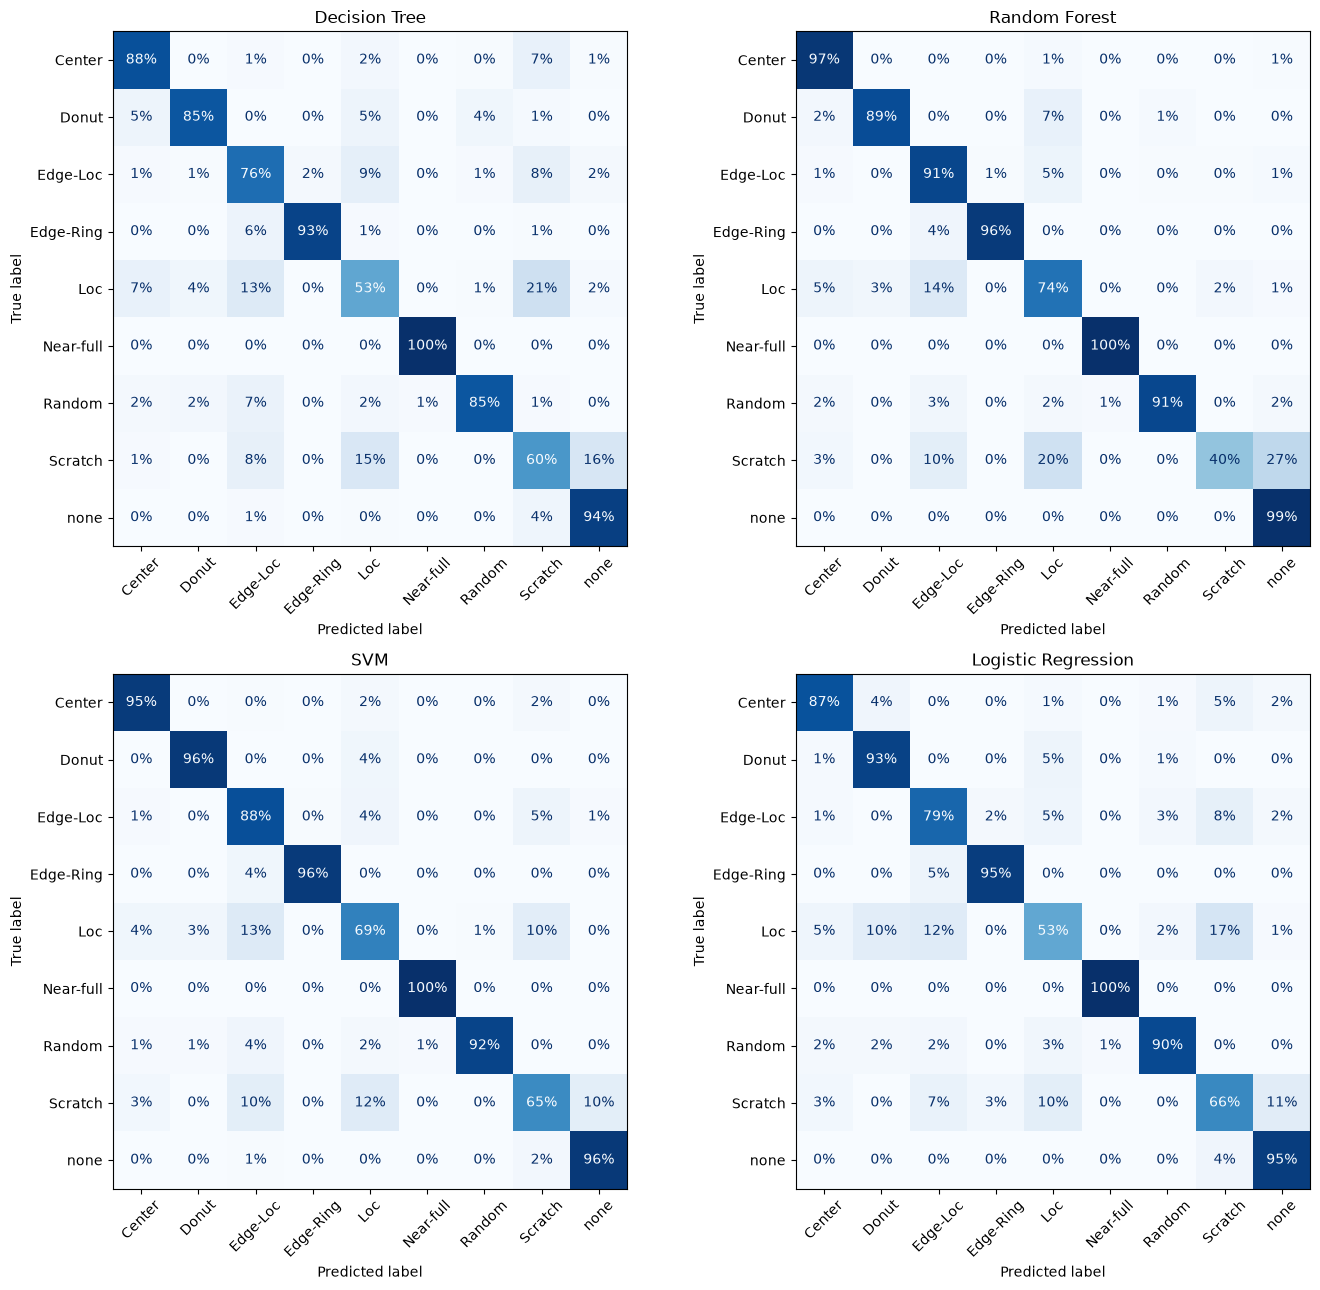

In [21]:
# Cell 21: confusion matrix for each model (rows = true class, shown as % of that row)
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(2, 2, figsize=(14, 13))           # 2 x 2 grid, one matrix per model
for ax, (name, pred) in zip(axes.ravel(), val_preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_val, pred,
        display_labels=CLASS_NAMES,       # class names along both edges
        normalize="true",                 # each row adds to 100%: share of that true class
        values_format=".0%",              # show as percentages with no decimals
        include_values=True,
        cmap="Blues",
        xticks_rotation=45,               # tilt the names so they fit
        ax=ax,
        colorbar=False,
    )
    ax.set_title(name)                    # which model this matrix belongs to
plt.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrices.png", dpi=150)  # save the image for the report
plt.show()

In [22]:
# Cell 22: detailed report for the best model on validation (chosen by macro-F1 in Stage 6)
from sklearn.metrics import classification_report
best_name = results["macro_F1"].idxmax()                  # the model with the highest macro-F1
print("Best model by validation macro-F1:", best_name)
print(classification_report(y_val, val_preds[best_name], labels=list(range(len(CLASS_NAMES))),
                            target_names=CLASS_NAMES, digits=3, zero_division=0))

Best model by validation macro-F1: Random Forest
              precision    recall  f1-score   support

      Center      0.955     0.973     0.964       693
       Donut      0.849     0.890     0.869        82
    Edge-Loc      0.747     0.911     0.821       483
   Edge-Ring      0.998     0.960     0.978      1711
         Loc      0.777     0.744     0.760       324
   Near-full      0.909     1.000     0.952        10
      Random      0.957     0.910     0.933       122
     Scratch      0.556     0.400     0.465       100
        none      0.994     0.993     0.993      7344

    accuracy                          0.968     10869
   macro avg      0.860     0.864     0.860     10869
weighted avg      0.969     0.968     0.968     10869



## Stage 8: Final test and save the model

Goal: produce the final score, once.

1. Retrain **Random Forest** (the validation winner, same settings) on the **whole** official Training set.
2. Score the official **Test set once**. We do not change anything after seeing these numbers.
3. Save the model with `joblib`, together with the feature names and class mapping, so the demo uses the same settings.
4. Reload the saved file and check it gives the same answers as the model in memory.

In [23]:
# Cell 25: retrain the chosen model on ALL training data, then score the test set ONCE
from sklearn.base import clone                              # makes a fresh, untrained copy of a model
from sklearn.metrics import precision_score                 # not used directly; kept for the report table below

final_model = clone(models["Random Forest"])                # same settings as the validation winner
final_model.fit(X_pool, y_pool)                             # learn from the whole official Training set

test_pred = final_model.predict(X_test)                     # predict the official Test set (first and only time)
is_defect_test = (y_test != NONE_ID).values                 # True where the test wafer really has a defect
test_flag = (test_pred != NONE_ID)                          # True where the model says "defect"

test_results = pd.Series({
    "accuracy": accuracy_score(y_test, test_pred),
    "macro_F1": f1_score(y_test, test_pred, average="macro"),
    "defect_recall": (test_flag & is_defect_test).sum() / is_defect_test.sum(),
}).round(4)
print("Test results (Random Forest):")
print(test_results.to_string())

report = pd.DataFrame(classification_report(
    y_test, test_pred, labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES, output_dict=True, zero_division=0)).T.round(3)
print("\nPer-class results on the test set:")
print(report.to_string())

test_results.to_csv(Path("../reports/test_results.csv"))    # save for the report
report.to_csv(Path("../reports/test_per_class.csv"))

Test results (Random Forest):
accuracy         0.9461
macro_F1         0.5745
defect_recall    0.8029

Per-class results on the test set:
              precision  recall  f1-score     support
Center            0.374   0.483     0.422     832.000
Donut             0.582   0.267     0.366     146.000
Edge-Loc          0.498   0.717     0.588    2772.000
Edge-Ring         0.677   0.571     0.619    1126.000
Loc               0.429   0.409     0.419    1973.000
Near-full         0.950   1.000     0.974      95.000
Random            0.750   0.677     0.712     257.000
Scratch           0.087   0.094     0.090     693.000
none              0.986   0.976     0.981  110701.000
accuracy          0.946   0.946     0.946       0.946
macro avg         0.593   0.577     0.575  118595.000
weighted avg      0.952   0.946     0.948  118595.000


In [24]:
# Cell 26: save the model with everything the demo needs, then check the saved file works
import joblib                                               # saves Python objects to a file

MODEL_PATH = Path("../models/wafer_defect_rf.joblib")       # where the model is saved
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)        # make sure the models folder exists

bundle = {                                                  # everything the demo needs, in one object
    "model": final_model,                                   # the trained Random Forest
    "feature_names": FEATURE_NAMES,                         # the 15 features, in the order the model expects
    "class_names": CLASS_NAMES,                             # index -> defect name
    "label_to_id": label_to_id,                             # defect name -> index
}
joblib.dump(bundle, MODEL_PATH)                             # write the file to disk
print("Saved to", MODEL_PATH.resolve(), "size (MB):", round(MODEL_PATH.stat().st_size / 1e6, 1))

# Reload and check: 5 test wafers, features from the raw map, same answers as the in-memory model
loaded = joblib.load(MODEL_PATH)                            # read the file back
idx5 = X_test.index[:5]                                     # five test wafers
feats = pd.DataFrame([extract_features(w) for w in labelled.loc[idx5, "waferMap"]])[loaded["feature_names"]]
saved_pred = loaded["model"].predict(feats)                 # predictions from the saved model
print("Predicted:", [loaded["class_names"][p] for p in saved_pred])
print("Actual:   ", labelled.loc[idx5, "failure"].tolist())
print("Saved model matches in-memory model:", bool((saved_pred == final_model.predict(X_test.iloc[:5])).all()))

Saved to C:\Users\Shashank Savarkar\OneDrive\Documents\TY ECE\5th Sem\AIML\Project\AIML_Project\models\wafer_defect_rf.joblib size (MB): 96.5
Predicted: ['none', 'none', 'none', 'none', 'none']
Actual:    ['none', 'none', 'none', 'none', 'none']
Saved model matches in-memory model: True


## Stage 9 (check): Does the class mix explain the test drop?

Diagnostic only. The test set is **not** used to change anything. We take the **validation** predictions and give each validation wafer a weight, so the validation class mix matches the test class mix. If the score then falls to about the test level, the drop comes mostly from the mix. If it stays high, the test lots differ in other ways.

In [ ]:
# Cell 28: re-weight the VALIDATION scores so the class mix matches the TEST mix
from sklearn.metrics import accuracy_score, f1_score

test_share = y_test.value_counts(normalize=True).sort_index()   # class shares in the official Test set
val_share = y_val.value_counts(normalize=True).sort_index()     # class shares in our validation part
class_weight_map = (test_share / val_share).to_dict()           # how much each class must count to match the test mix
w = y_val.map(class_weight_map).values                          # one weight per validation wafer

is_def = (y_val != NONE_ID).values
rows = []
for name, pred in val_preds.items():
    flag = (pred != NONE_ID)
    rows.append({
        "model": name,
        "macro_F1 (plain validation)": f1_score(y_val, pred, average="macro"),
        "macro_F1 (re-weighted to test mix)": f1_score(y_val, pred, average="macro", sample_weight=w),
        "accuracy (re-weighted)": accuracy_score(y_val, pred, sample_weight=w),
        "defect recall (re-weighted)": float(np.sum(w * (flag & is_def)) / np.sum(w * is_def)),
    })
mix_check = pd.DataFrame(rows).set_index("model").round(3)
print(mix_check.to_string())
print("\nFor comparison, Random Forest on the official Test set: macro-F1", round(test_results["macro_F1"], 3),
      " accuracy", round(test_results["accuracy"], 3), " defect recall", round(test_results["defect_recall"], 3))
mix_check.to_csv(Path("../reports/validation_mix_check.csv"))

## Stage 9: Demo application

The demo needs only the trained model, the feature code and a few example wafers. It does not need the 2 GB dataset. First we save one example wafer per class (from the official Test set) to a small file. The app itself is in `app/streamlit_app.py`.

In [ ]:
# Cell 30: save one example test wafer per class, so the demo app can run without the 2 GB dataset
import joblib

demo_samples = []
for name in CLASS_NAMES:                                       # one example for each defect category
    row = labelled[(labelled["failure"] == name) & (labelled["split"] == "Test")].sample(1, random_state=7).iloc[0]
    demo_samples.append({"true_label": name, "waferMap": np.asarray(row["waferMap"])})

joblib.dump(demo_samples, Path("../data/processed/demo_samples.joblib"))  # small file, saved next to the features
print("Saved", len(demo_samples), "example wafers:", [s["true_label"] for s in demo_samples])